# 07 – Word2Vec, ảnh hưởng của tiền xử lý, thí nghiệm văn bản không dấu

1. **Word2Vec + LR**: thuật toán nâng cao thứ 3 (biểu diễn dày, nắm ngữ nghĩa từ).
2. **Thí nghiệm tiền xử lý** (P3.3): TF-IDF+LR với 4 mức tiền xử lý.
3. **Thí nghiệm không dấu** (P5, fairness): người gõ không dấu có bị mô hình bất lợi không, và dữ liệu Aug có giúp không?

Tất cả huấn luyện trên **A+B**, dùng tham số tốt nhất từ notebook 06 (ngram (1,2), min_df 1, C 3).

In [1]:
import sys, os
sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gensim.models import Word2Vec
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from src.data import load_sets, load_gold
from src.preprocess import normalize_text, preprocess, remove_stopwords, strip_accents

FIG, REP = "../figures", "../report"
S = load_sets()
gold, GOLD_TEMP = load_gold()
print("Tập vàng:", "TẠM nhãn sao" if GOLD_TEMP else "nhãn tay", len(gold))
AB = pd.concat([S["A"], S["B"]], ignore_index=True)
ABAug = pd.concat([S["A"], S["B"], S["Aug"]], ignore_index=True)
A_test = S["A_test"]

def tfidf_lr():
    return make_pipeline(TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), min_df=1),
                         LogisticRegression(C=3, max_iter=3000, class_weight="balanced"))

def f1(y, p):
    return round(f1_score(y, p, average="macro"), 3)

Tập vàng: TẠM nhãn sao 746


## 1. Word2Vec + Logistic Regression

Huấn luyện Word2Vec (skip-gram) trên toàn bộ văn bản train đã tách từ (A+B+Aug, khoảng 10 nghìn câu). Vector câu = trung bình vector các từ (mean pooling), nên **mất trật tự từ**: "không tốt" và "tốt không" giống nhau.

In [2]:
corpus = [s.split() for s in ABAug.text_prep]
w2v = Word2Vec(corpus, vector_size=200, window=5, min_count=2, sg=1, epochs=20, seed=42, workers=1)
print("Từ vựng:", len(w2v.wv))
for w in ["tệ", "giao_hàng", "đẹp", "rẻ"]:
    if w in w2v.wv:
        print(f"{w:10s} ->", ", ".join(f"{t}({s:.2f})" for t, s in w2v.wv.most_similar(w, topn=8)))

Từ vựng: 7778
tệ         -> dở(0.60), tệ_hại(0.58), tồi_tệ(0.58), phanh(0.57), nhanh_tụt(0.57), thảm_họa(0.56), dỡ(0.56), máy_tệ(0.56)
đẹp        -> xóa_phong(0.68), !_camera(0.68), đẹppin(0.68), thiêt(0.68), ổn_màng(0.68), hình_sắc(0.68), bắt_mắt(0.67), hình_đẹp(0.67)
rẻ         -> hời(0.63), siêu_rẻ(0.61), xịn_sò(0.61), sịn(0.59), xù(0.59), tôm(0.59), mua_lẻ(0.58), ngon_bổ(0.57)


In [3]:
def sent_vec(texts):
    out = np.zeros((len(texts), w2v.vector_size))
    for i, s in enumerate(texts):
        vs = [w2v.wv[t] for t in s.split() if t in w2v.wv]
        if vs:
            out[i] = np.mean(vs, axis=0)
    return out

w2v_rows = []
for C in [0.1, 1, 10]:
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000, class_weight="balanced"))
    clf.fit(sent_vec(S["A"].text_prep.tolist() + S["B"].text_prep.tolist()), AB.label)
    w2v_rows.append({"C": C, "F1_A_dev": f1(S["A_dev"].label, clf.predict(sent_vec(S["A_dev"].text_prep))),
                     "F1_ViSD_test": f1(A_test.label, clf.predict(sent_vec(A_test.text_prep))),
                     "F1_gold": f1(gold.label, clf.predict(sent_vec(gold.text_prep)))})
w2v_res = pd.DataFrame(w2v_rows)
w2v_res.to_csv(f"{REP}/word2vec_results.csv", index=False)
print("Chọn C theo F1_A_dev (không theo tập vàng):")
w2v_res

Chọn C theo F1_A_dev (không theo tập vàng):


,C,F1_A_dev,F1_ViSD_test,F1_gold
0,0.1,0.644,0.625,0.562
1,1.0,0.636,0.622,0.558
2,10.0,0.637,0.621,0.556


**Tự kiểm tra:** Các từ gần "tệ" có hợp lý không? Vì sao Word2Vec + trung bình thường **kém** TF-IDF bigram ở bài cảm xúc? (Gợi ý: phủ định, trật tự từ.)

## 2. Ảnh hưởng của tiền xử lý

| Biến thể | Văn bản đưa vào TF-IDF |
|---|---|
| (1) Thô | văn bản gốc, chỉ viết thường |
| (2) Chuẩn hóa | NFC, viết thường, emoji → chữ, teencode, gộp ký tự lặp |
| (3) + tách từ | (2) + underthesea `word_tokenize` (= cột `text_prep`) |
| (4) + bỏ stopword | (3) + bỏ stopword, **giữ từ phủ định** |

In [4]:
def variants(df):
    return {"(1) Thô": df.text_raw.str.lower(),
            "(2) Chuẩn hóa": df.text_raw.map(normalize_text),
            "(3) + Tách từ": df.text_prep,
            "(4) + Bỏ stopword (giữ phủ định)": df.text_prep.map(remove_stopwords)}

V_tr, V_test, V_gold = variants(AB), variants(A_test), variants(gold)
pre_rows = []
for k in V_tr:
    m = tfidf_lr().fit(V_tr[k], AB.label)
    pre_rows.append({"Biến thể": k, "Số từ vựng": len(m[0].vocabulary_),
                     "F1_ViSD_test": f1(A_test.label, m.predict(V_test[k])),
                     "F1_gold": f1(gold.label, m.predict(V_gold[k]))})
pre_res = pd.DataFrame(pre_rows)
pre_res.to_csv(f"{REP}/preprocess_ablation.csv", index=False)
pre_res

,Biến thể,Số từ vựng,F1_ViSD_test,F1_gold
0,(1) Thô,102437,0.713,0.654
1,(2) Chuẩn hóa,98160,0.699,0.657
2,(3) + Tách từ,110692,0.713,0.612
3,(4) + Bỏ stopword (giữ phủ định),104527,0.731,0.618


**Nhận xét (tự viết):** Bước nào giúp nhiều nhất? Nếu bỏ stopword làm giảm F1, giải thích vì sao (các từ như "nhưng", "mà" mang tín hiệu đối lập). Số từ vựng giảm thì mô hình gọn hơn, có ý nghĩa gì với việc triển khai?

## 3. Văn bản không dấu

Bỏ dấu toàn bộ tập vàng (và ViSD4SA test) rồi tiền xử lý lại. So mô hình huấn luyện trên **A+B** (gần như toàn bộ có dấu) và **A+B+Aug** (có thêm 1.205 câu không dấu).

In [5]:
def unaccent_prep(texts):
    return [preprocess(strip_accents(t)) for t in texts]

gold_ua = unaccent_prep(gold.text_raw)
test_ua = unaccent_prep(A_test.text_raw)
print("Ví dụ:", gold.text_raw.iloc[3][:80], "->", gold_ua[3][:80])

ua_rows = []
for cfg, d in [("A+B", AB), ("A+B+Aug", ABAug)]:
    m = tfidf_lr().fit(d.text_prep, d.label)
    ua_rows.append({"Train": cfg,
                    "ViSD test có dấu": f1(A_test.label, m.predict(A_test.text_prep)),
                    "ViSD test không dấu": f1(A_test.label, m.predict(test_ua)),
                    "Vàng có dấu": f1(gold.label, m.predict(gold.text_prep)),
                    "Vàng không dấu": f1(gold.label, m.predict(gold_ua))})
ua_res = pd.DataFrame(ua_rows)
ua_res.to_csv(f"{REP}/unaccent_results.csv", index=False)
ua_res

Ví dụ: tốt Sao tôi mua 5 nhưng nhận hàng có 3. Shop đã đóng nhầm hàng cho tôi. Cần sự p -> tot sao toi mua 5 nhung nhan_hang co 3 . cửa_hàng da_dong nham hang cho toi . ca


,Train,ViSD test có dấu,ViSD test không dấu,Vàng có dấu,Vàng không dấu
0,A+B,0.713,0.481,0.612,0.458
1,A+B+Aug,0.717,0.457,0.618,0.527


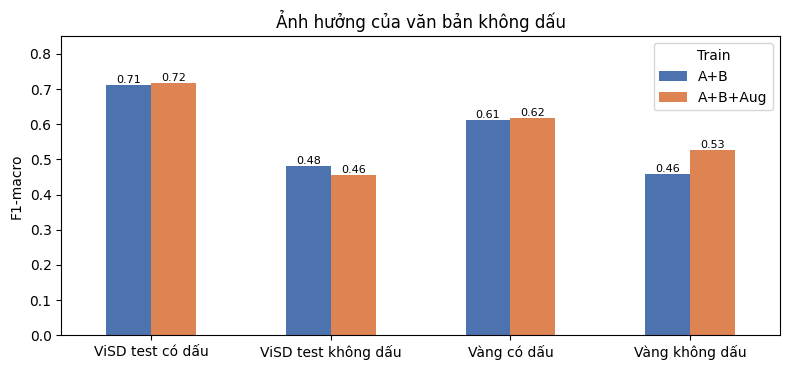

In [6]:
ax = ua_res.set_index("Train").T.plot.bar(figsize=(8, 3.8), rot=0, color=["#4C72B0", "#DD8452"])
ax.set(ylabel="F1-macro", title="Ảnh hưởng của văn bản không dấu", ylim=(0, 0.85))
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/unaccent.png", bbox_inches="tight"); plt.show()

**Nhận xét (tự viết, đưa vào P5 mục Fairness):** F1 giảm bao nhiêu khi người dùng gõ không dấu? Dữ liệu Aug lấy lại được bao nhiêu phần? Nhóm người dùng nào hay gõ không dấu (điện thoại cũ, người lớn tuổi, gõ nhanh)? Nếu không xử lý, mô hình sẽ **bỏ sót lời chê của chính nhóm này**.